# Stuctural Learning

Structure learning lets the data speak before we impose a directed acyclic graph (DAG) drawn from domain knowledge alone. This analysis is exploratory, not confirmatory. It asks: which variables are conditionally dependent on which others, and what does that pattern suggest about the causal architecture?

The PC algorithm (Spirtes and Glymour, 1991) recovers a completed partially directed acyclic graph (CPDAG) from a sequence of conditional-independence (CI) tests. It assumes the Markov condition (every variable is independent of its non-descendants given its parents), faithfulness (every observed independence reflects a d-separation in the true graph) and causal sufficiency (no unmeasured common causes). Each of these assumptions will be scrutinized against the realities of this dataset (Spirtes, Glymour and Scheines, 2000).

We first check whether the Gaussian linearity assumption behind the standard Fisher-z test is defensible, then run the PC algorithm under three different CI tests and interpret what the resulting graphs say about smoking cessation and weight change.

## 1. Setup

Libraries, output directories and reproducibility seed.

In [17]:
import warnings; warnings.filterwarnings("ignore")
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from causallearn.search.ConstraintBased.PC import pc
from causallearn.utils.cit import fisherz, chisq, kci
from causallearn.utils.GraphUtils import GraphUtils
from causallearn.utils.PCUtils.BackgroundKnowledge import BackgroundKnowledge
from IPython.display import Image, display
np.random.seed(42)
os.makedirs("../outputs/figures", exist_ok=True)
os.makedirs("../outputs/tables", exist_ok=True)

In [18]:
from pathlib import Path
import pandas as pd

project_dir = Path.cwd()
data_dir = project_dir / "data"

print("project_dir:", project_dir)
print("data_dir:", data_dir)

df = pd.read_csv(data_dir / "nhefs_complete.csv")
codebook = pd.read_csv(data_dir / "nhefs_codebook.csv")

project_dir: /Users/mirceaadrianguinea/Desktop/BSE_DS/Projects/Q2/Causal/project-smoking-weight-amt
data_dir: /Users/mirceaadrianguinea/Desktop/BSE_DS/Projects/Q2/Causal/project-smoking-weight-amt/data


## 2. Data Loading

We load the NHEFS dataset used throughout Hernan and Robins (2020).

In [19]:
#df = pd.read_csv("../data/nhefs_complete.csv")
#codebook = pd.read_csv("../data/nhefs_codebook.csv")
print(f"Shape: {df.shape}")
print(f"qsmk prevalence: {df['qsmk'].mean():.3f}")
print(f"wt82_71 mean: {df['wt82_71'].mean():.2f} kg, SD: {df['wt82_71'].std():.2f} kg")

Shape: (1566, 67)
qsmk prevalence: 0.257
wt82_71 mean: 2.64 kg, SD: 7.88 kg


About a quarter of the cohort quit smoking between baseline and 1982. The average weight change is positive (roughly 2.6 kg), suggesting that quitting may be associated with weight gain. But this is a crude average that conflates any treatment effect with confounding by variables that predict both cessation and weight change.

## 3. Variable Selection

We retain pre-treatment covariates that plausibly participate in the causal structure around smoking cessation and weight change. We drop identifiers, post-treatment descendants, instruments, rare conditions and variables with heavy missingness.

| Category | Dropped | Reason |
|---|---|---|
| Identifiers | seqn, id | No causal content |
| Post-treatment mortality | death, yrdth, modth, dadth | Collider descendants; conditioning opens bias paths (Hernan and Robins, 2020, Ch. 8) |
| Post-treatment measures | sbp, dbp, wt82, smkintensity82_71 | Measured after treatment window |
| Redundant / instruments | school, price/tax variables, hightax82 | Instruments not confounders (Hernan and Robins, 2020, Ch. 16) |
| Rare conditions | tb, hf, polio, hepatitis, pica | Fewer than 20 cases; CI tests lack power |
| Heavy missingness | pregnancies, alcoholhowmuch | 55% and 25% missing; naive deletion biases PC (Tu et al., 2019) |
| Miscellaneous | birthplace, censored, older, birthcontrol | Derived indicators or high-cardinality |

In [20]:
drop_cols = [
    'seqn', 'id',
    'death', 'yrdth', 'modth', 'dadth',
    'sbp', 'dbp', 'wt82', 'smkintensity82_71',
    'school', 'price71', 'price82', 'tax71', 'tax82',
    'price71_82', 'tax71_82', 'hightax82',
    'tb', 'hf', 'polio', 'hepatitis', 'pica',
    'pregnancies', 'alcoholhowmuch',
    'birthplace', 'censored', 'older', 'birthcontrol',
]
df_sel = df.drop(columns=[c for c in drop_cols if c in df.columns])
print(f"Retained {df_sel.shape[1]} variables:")
print(list(df_sel.columns))

sel_table = pd.DataFrame({
    'Category': ['Identifiers', 'Post-treatment mortality', 'Post-treatment measures',
                 'Redundant / instruments', 'Rare conditions', 'Heavy missingness', 'Miscellaneous'],
    'Dropped': ['seqn, id', 'death, yrdth, modth, dadth', 'sbp, dbp, wt82, smkintensity82_71',
                'school, price/tax variables, hightax82', 'tb, hf, polio, hepatitis, pica',
                'pregnancies, alcoholhowmuch', 'birthplace, censored, older, birthcontrol'],
    'Reason': ['No causal content', 'Collider descendants', 'Measured after treatment window',
               'Instruments not confounders', 'Fewer than 20 cases', '55% and 25% missing',
               'Derived indicators or high-cardinality']
})
sel_table.to_csv("../outputs/tables/variable_selection.csv", index=False)

Retained 38 variables:
['qsmk', 'sex', 'age', 'race', 'income', 'marital', 'education', 'ht', 'wt71', 'wt82_71', 'smokeintensity', 'smokeyrs', 'asthma', 'bronch', 'hbp', 'pepticulcer', 'colitis', 'chroniccough', 'hayfever', 'diabetes', 'tumor', 'nervousbreak', 'alcoholpy', 'alcoholfreq', 'alcoholtype', 'headache', 'otherpain', 'weakheart', 'allergies', 'nerves', 'lackpep', 'hbpmed', 'boweltrouble', 'wtloss', 'infection', 'active', 'exercise', 'cholesterol']


## 4. Missing Data Assessment

This section replaces a silent `dropna()`. The missing-data question deserves explicit confrontation.

### 4a. Missingness report

In [21]:
miss = df_sel.isnull().sum().reset_index()
miss.columns = ['variable', 'n_missing']
miss['pct_missing'] = (miss['n_missing'] / len(df_sel) * 100).round(2)
miss = miss.sort_values('n_missing', ascending=False)
print(miss[miss['n_missing'] > 0].to_string(index=False))
miss.to_csv("../outputs/tables/missingness_report.csv", index=False)

   variable  n_missing  pct_missing
     income         59         3.77
cholesterol         16         1.02


Most variables are complete if we look only at explicit `NaN` values. Income and cholesterol are the main standard missing-data issues at this stage.

However, NHEFS also uses **non-standard missingness codes** in a few variables. Before running PC, we therefore harmonize the main coded-missing cases that are documented in the codebook: variables with `2 = Missing`, plus `marital = 8 (Unknown)` and `alcoholfreq = 5 (Unknown)`. This ensures that the conditional-independence tests operate on a cleaner complete-case sample.

### 4b. Is missingness random?

In [22]:
for var in ['income', 'cholesterol']:
    missing_flag = df_sel[var].isnull().astype(int)
    ct = pd.crosstab(missing_flag, df_sel['qsmk'])
    chi2, p, _, _ = stats.chi2_contingency(ct)
    print(f"\n{var} missingness vs qsmk: chi2={chi2:.3f}, p={p:.4f}")
    obs_mean = df_sel.loc[df_sel[var].notna(), 'wt82_71'].mean()
    mis_mean = df_sel.loc[df_sel[var].isna(), 'wt82_71'].mean()
    print(f"  wt82_71 mean (observed): {obs_mean:.2f}, (missing): {mis_mean:.2f}")


income missingness vs qsmk: chi2=6.374, p=0.0116
  wt82_71 mean (observed): 2.61, (missing): 3.31

cholesterol missingness vs qsmk: chi2=0.864, p=0.3525
  wt82_71 mean (observed): 2.63, (missing): 3.31


Income missingness is significantly associated with qsmk (p ~ 0.01). The data are **not** MCAR for income. Cholesterol missingness shows no significant association with treatment status. When data are not MCAR, complete-case deletion can distort conditional-independence tests and produce spurious or missing edges in the learned graph (Tu et al., 2019).

### 4c. Decision

We use complete-case deletion despite the MCAR violation because the alternative is worse. Multiple imputation fills in values by modeling the conditional distribution of the missing variable given the observed variables. But that imputation model introduces *artificial* conditional dependencies. If the model is misspecified, the PC algorithm picks up edges that reflect the imputation rather than the data-generating process (Gain and Shpitser, 2018).

With only 3.8 percent missing on income (the worst case), the bias from complete-case deletion is likely small. We lose roughly 74 observations. We accept this cost.

A robustness check using the MVPC algorithm of Tu et al. (2019), available in `causal-learn` via the `mvpc=True` flag, would be a valuable next step.

In [23]:
# Harmonize the main coded-missing values before complete-case analysis
df_harmonized = df_sel.copy()

# Fix known codebook typos so variable matching is reliable
codebook["variable"] = codebook["variable"].replace({
    "bithcontrol": "birthcontrol",
    "smkintensity 82_71": "smkintensity82_71"
})

mask_2_missing = codebook["description"].str.contains(
    r"2\s*:\s*MISSING", case=False, na=False, regex=True
)
vars_2_missing = codebook.loc[mask_2_missing, "variable"].tolist()
vars_2_missing = [c for c in vars_2_missing if c in df_harmonized.columns]

special_missing_codes = {c: 2 for c in vars_2_missing}
if "marital" in df_harmonized.columns:
    special_missing_codes["marital"] = 8
if "alcoholfreq" in df_harmonized.columns:
    special_missing_codes["alcoholfreq"] = 5

special_missing_summary = pd.DataFrame({
    "variable": list(special_missing_codes.keys()),
    "missing_code": list(special_missing_codes.values()),
    "n_special_code": [(df_harmonized[v] == code).sum() for v, code in special_missing_codes.items()],
    "n_nan_before": [df_harmonized[v].isna().sum() for v in special_missing_codes.keys()]
}).sort_values("n_special_code", ascending=False)

display(special_missing_summary)
special_missing_summary.to_csv("../outputs/tables/coded_missing_summary.csv", index=False)

for var, miss_code in special_missing_codes.items():
    df_harmonized[var] = df_harmonized[var].replace(miss_code, np.nan)

df_clean = df_harmonized.dropna()
print(f"Sample size after harmonizing coded missingness and dropping incomplete rows: {len(df_clean)} "
      f"(lost {len(df_harmonized) - len(df_clean)})")

,variable,missing_code,n_special_code,n_nan_before
1,boweltrouble,2,769,0
2,diabetes,2,769,0
3,hbp,2,769,0
4,hbpmed,2,769,0
0,alcoholpy,2,5,0
6,alcoholfreq,5,5,0
5,marital,8,1,0


Sample size after harmonizing coded missingness and dropping incomplete rows: 761 (lost 805)


## 5. Variable Classification

We classify variables as continuous (6 or more unique values) or discrete (5 or fewer). This determines which CI test is appropriate for each subset.

In [24]:
nunique = df_clean.nunique()
continuous_vars = sorted(nunique[nunique >= 6].index.tolist())
discrete_vars = sorted(nunique[nunique < 6].index.tolist())

vtype_df = pd.DataFrame({
    'variable': df_clean.columns,
    'n_unique': [df_clean[c].nunique() for c in df_clean.columns],
    'type': ['continuous' if c in continuous_vars else 'discrete' for c in df_clean.columns]
})
print(f"Continuous ({len(continuous_vars)}): {continuous_vars}")
print(f"Discrete ({len(discrete_vars)}): {discrete_vars}")
vtype_df.to_csv("../outputs/tables/variable_types.csv", index=False)

Continuous (8): ['age', 'cholesterol', 'ht', 'income', 'smokeintensity', 'smokeyrs', 'wt71', 'wt82_71']
Discrete (30): ['active', 'alcoholfreq', 'alcoholpy', 'alcoholtype', 'allergies', 'asthma', 'boweltrouble', 'bronch', 'chroniccough', 'colitis', 'diabetes', 'education', 'exercise', 'hayfever', 'hbp', 'hbpmed', 'headache', 'infection', 'lackpep', 'marital', 'nerves', 'nervousbreak', 'otherpain', 'pepticulcer', 'qsmk', 'race', 'sex', 'tumor', 'weakheart', 'wtloss']


## 6. Gaussian Linearity Diagnostics

This section checks the assumptions behind the Fisher-z test before any PC variant is run.

### 6a. Why this matters

The Fisher-z test checks whether the partial correlation between two variables, conditional on a set S, is zero. Under multivariate Gaussianity, zero partial correlation is equivalent to conditional independence (Spirtes, Glymour and Scheines, 2000, Chapter 5). If the joint distribution is not Gaussian, two problems arise. First, the p-values from the Fisher-z test may be miscalibrated: heavy tails inflate the test statistic and make it reject too often (anti-conservative). Second, nonlinear relationships can produce zero partial correlation even when the variables are strongly dependent, so the test misses real edges.

There is a partial defense. The t-statistic underlying the Fisher-z test is based on a ratio of sample moments, and by the central limit theorem it is approximately normal for large n even if the marginals are not Gaussian. With n ~ 1500, this robustness argument has some force. But it does not rescue the test against heavy tails or nonlinearity. We need to check both.

### 6b. Univariate normality

In [25]:
norm_results = []
for c in continuous_vars:
    x = df_clean[c].values
    sw_stat, sw_p = stats.shapiro(x[:5000])
    sk = stats.skew(x)
    ku = stats.kurtosis(x)
    norm_results.append({'variable': c, 'shapiro_p': f"{sw_p:.2e}", 'skewness': round(sk, 2),
                         'excess_kurtosis': round(ku, 2),
                         'flag': '***' if (abs(sk) > 1 or ku > 2) else ''})

norm_df = pd.DataFrame(norm_results)
print(norm_df.to_string(index=False))
norm_df.to_csv("../outputs/tables/normality_tests.csv", index=False)

      variable shapiro_p  skewness  excess_kurtosis flag
           age  1.26e-11      0.10            -0.95     
   cholesterol  6.68e-08      0.54             0.72     
            ht  4.94e-04      0.14            -0.48     
        income  5.46e-22     -0.85             0.00     
smokeintensity  4.38e-19      0.70             0.52     
      smokeyrs  6.12e-08      0.27            -0.59     
          wt71  2.74e-13      0.89             1.64     
       wt82_71  1.64e-13      0.40             3.38  ***


Every variable rejects Shapiro-Wilk at p < 0.001. This is expected with n ~ 1500; the test is very powerful and will reject even mild departures. Shapiro-Wilk alone is not very informative here. What matters is the *shape* of the departure.

`smokeintensity` is right-skewed (skewness ~ 0.74). This makes sense: most smokers are moderate; a tail of heavy smokers pulls the distribution right. This is a count-like variable, not a Gaussian one.

`wt82_71` has excess kurtosis of roughly 3.7. The tails are heavier than Gaussian. A few people gained or lost 30-40 kg. These extreme observations will inflate partial correlations and make Fisher-z anti-conservative.

`income` is left-skewed (-0.90) because the NHEFS coded income in ordinal brackets (11 = under $1000 through 22 = $25000+), not continuous dollars. Treating this as continuous is a stretch. `age` and `ht` have mild departures (|skewness| < 0.3) and are the closest to Gaussian.

### 6c. Q-Q plots

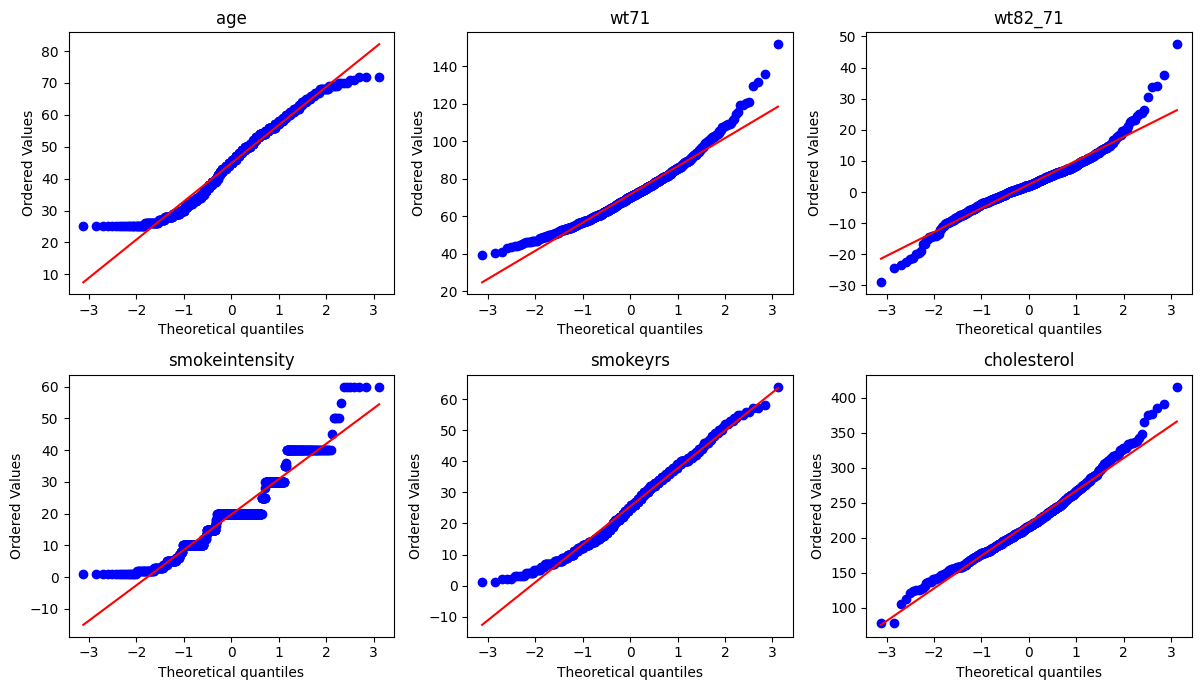

In [26]:
qq_vars = ['age', 'wt71', 'wt82_71', 'smokeintensity', 'smokeyrs', 'cholesterol']
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, v in zip(axes.ravel(), qq_vars):
    stats.probplot(df_clean[v].values, dist='norm', plot=ax)
    ax.set_title(v)
plt.tight_layout()
plt.savefig("../outputs/figures/qq_plots.png", dpi=150, bbox_inches="tight")
plt.show()

**Figure 1.** Q-Q plots. Departures from the diagonal indicate non-Gaussianity. Note the heavy right tail of smokeintensity and the heavy tails of wt82_71.

### 6d. Linearity check

In [27]:
cont_data = df_clean[continuous_vars]
pearson_corr = cont_data.corr(method='pearson')
spearman_corr = cont_data.corr(method='spearman')
diff = (pearson_corr - spearman_corr).abs()

pairs = []
cols = diff.columns
for i in range(len(cols)):
    for j in range(i+1, len(cols)):
        pairs.append({'var1': cols[i], 'var2': cols[j],
                      'pearson': round(pearson_corr.iloc[i, j], 3),
                      'spearman': round(spearman_corr.iloc[i, j], 3),
                      'abs_diff': round(diff.iloc[i, j], 3)})

lin_df = pd.DataFrame(pairs).sort_values('abs_diff', ascending=False)
print(lin_df.head(10).to_string(index=False))
lin_df.to_csv("../outputs/tables/linearity_check.csv", index=False)

          var1           var2  pearson  spearman  abs_diff
        income       smokeyrs   -0.181    -0.138     0.043
   cholesterol       smokeyrs    0.158     0.193     0.035
           age         income   -0.190    -0.156     0.034
          wt71        wt82_71   -0.126    -0.100     0.026
           age           wt71   -0.023     0.001     0.024
            ht smokeintensity    0.223     0.248     0.024
           age    cholesterol    0.256     0.279     0.023
        income smokeintensity    0.107     0.130     0.023
smokeintensity        wt82_71    0.055     0.034     0.021
            ht        wt82_71    0.040     0.019     0.021


If Spearman (rank-based) diverges substantially from Pearson (linear), the relationship has a nonlinear component that Fisher-z cannot detect. Most pairs show small gaps, suggesting that the dominant relationships are approximately monotone. Where larger gaps appear, they typically involve income or smokeintensity, consistent with the distributional concerns noted above.

### 6e. Verdict

The Gaussian linearity assumption is violated in this dataset. Several variables show material skewness and kurtosis, and income is ordinal rather than continuous.

We therefore treat Fisher-z as a **fast approximate screen**, not as the main graph for treatment and outcome. For the final mixed-variable graph we use a smaller set of scientifically plausible pre-treatment covariates, harmonize missingness first, and impose temporal background knowledge so that post-treatment variables cannot point back to treatment.

## 7. Tiered PC with Fisher-z (fast approximate screen)

> Fisher-z tests partial correlation = 0, which equals conditional independence under Gaussianity. Here it is used only as a **quick approximate screen** on a smaller, temporally constrained variable set. Because `qsmk` is binary and several variables are non-Gaussian, the Fisher-z graph should not be treated as the main result.

### alpha = 0.05

  0%|          | 0/14 [00:00<?, ?it/s]

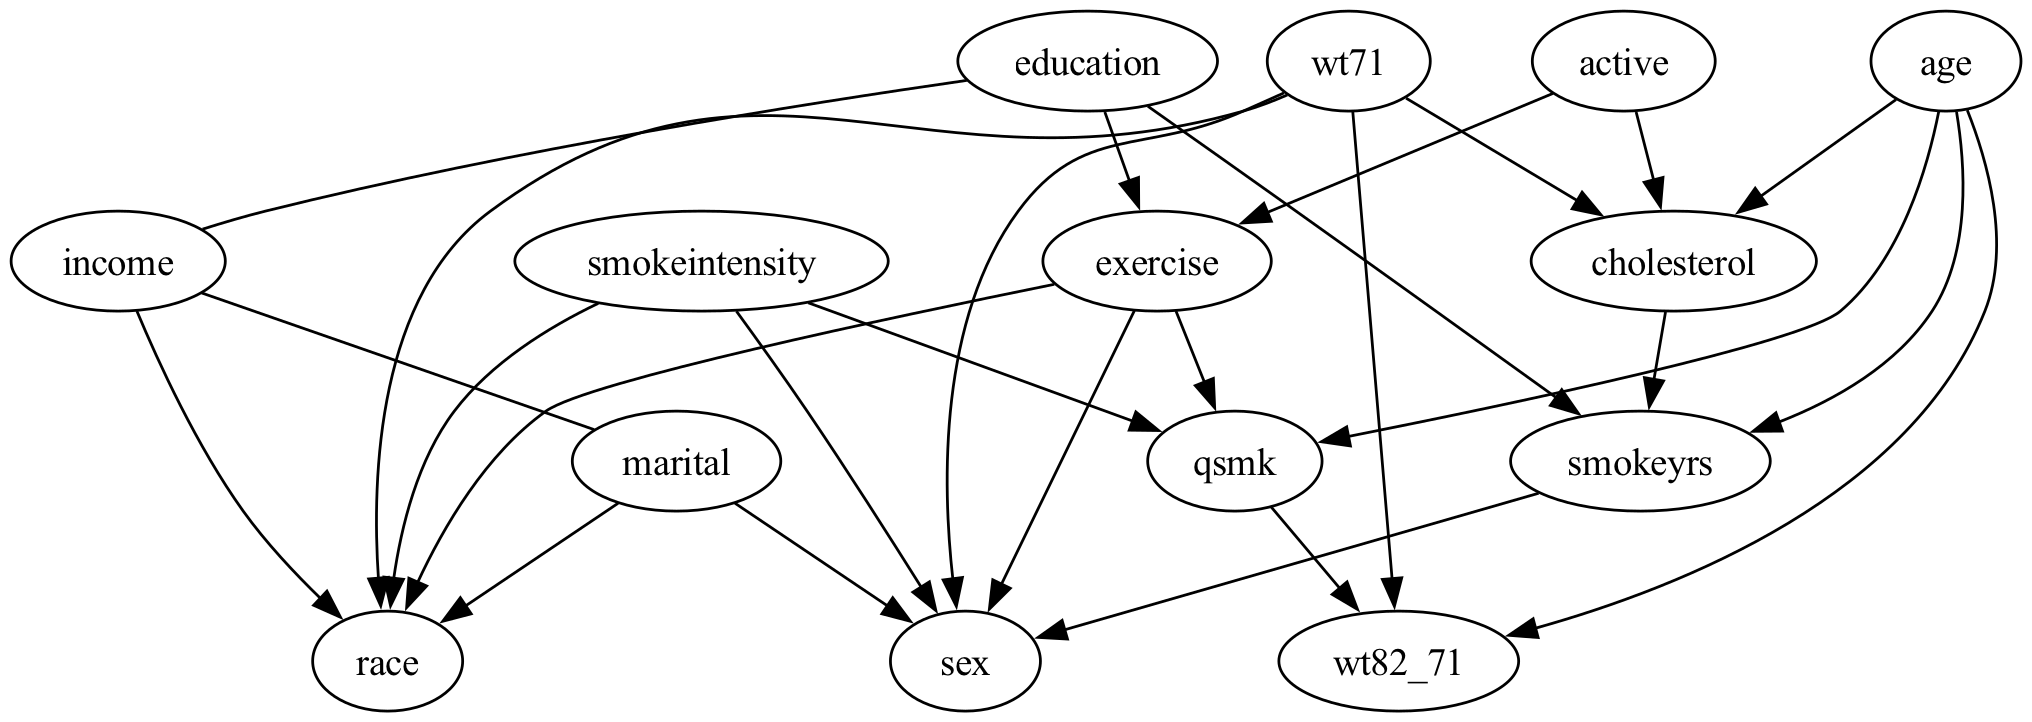

In [28]:
# Smaller, more plausible pre-treatment set for graph discovery
pc_vars_main = [
    'age', 'sex', 'race', 'education', 'income', 'marital',
    'wt71', 'smokeintensity', 'smokeyrs', 'exercise',
    'active', 'cholesterol', 'qsmk', 'wt82_71'
]
pc_vars_main = [v for v in pc_vars_main if v in df_clean.columns]

pretreat_main = [v for v in pc_vars_main if v not in ['qsmk', 'wt82_71']]
df_pc = df_clean[pc_vars_main].copy()

def build_temporal_background_knowledge(pretreat, treatment='qsmk', outcome='wt82_71',
                                        require_treatment_to_outcome=False):
    bk = BackgroundKnowledge()
    for v in pretreat:
        # treatment and later outcome cannot cause baseline variables
        bk = bk.add_forbidden_by_pattern(fr'^{treatment}$', fr'^{v}$')
        bk = bk.add_forbidden_by_pattern(fr'^{outcome}$', fr'^{v}$')
    # later weight change cannot cause treatment
    bk = bk.add_forbidden_by_pattern(fr'^{outcome}$', fr'^{treatment}$')
    if require_treatment_to_outcome:
        bk = bk.add_required_by_pattern(fr'^{treatment}$', fr'^{outcome}$')
    return bk

bk_main = build_temporal_background_knowledge(
    pretreat_main,
    treatment='qsmk',
    outcome='wt82_71',
    require_treatment_to_outcome=False
)

# Fast approximate Fisher-z run on the temporally constrained mixed set
fisherz_data = df_pc.values.astype(float)
fisherz_labels = pc_vars_main

cg_fz05 = pc(
    fisherz_data,
    alpha=0.05,
    indep_test=fisherz,
    stable=True,
    background_knowledge=bk_main,
    node_names=fisherz_labels
)

pdy = GraphUtils.to_pydot(cg_fz05.G, labels=fisherz_labels)
pdy.write_png("../outputs/figures/cpdag_fisherz_05_tiered.png")
display(Image("../outputs/figures/cpdag_fisherz_05_tiered.png"))

**Figure 2.** Tiered CPDAG, Fisher-z, alpha = 0.05.

### alpha = 0.01

  0%|          | 0/14 [00:00<?, ?it/s]

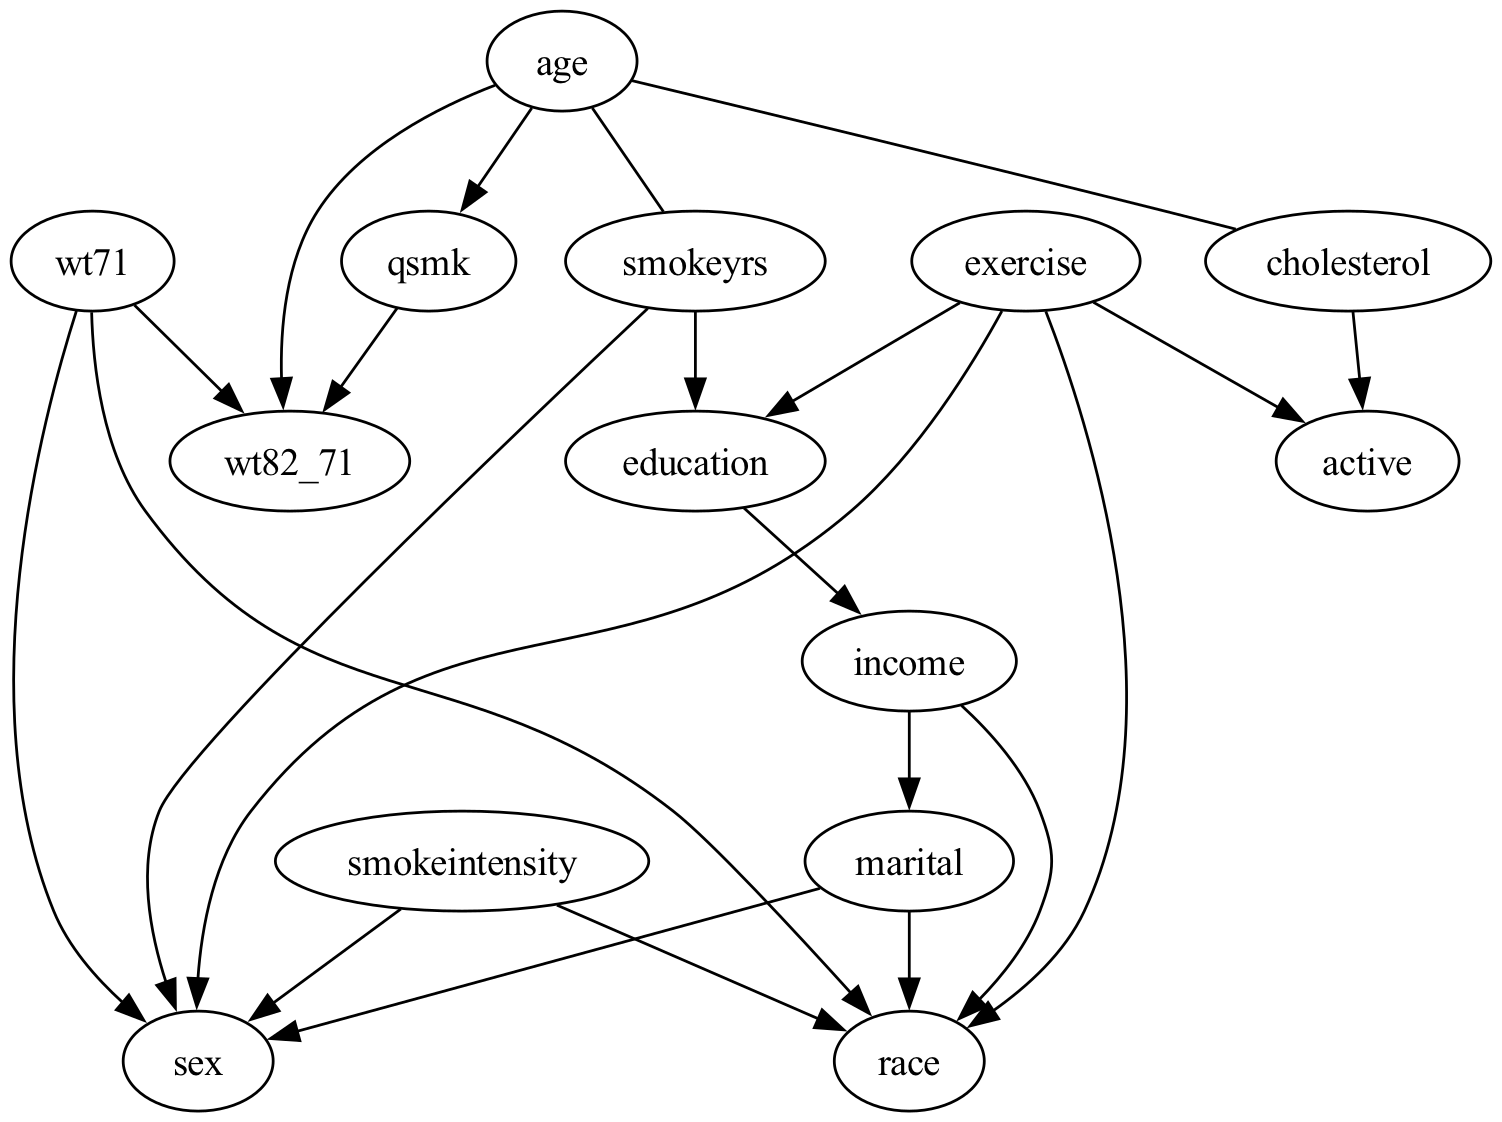

In [29]:
cg_fz01 = pc(
    fisherz_data,
    alpha=0.01,
    indep_test=fisherz,
    stable=True,
    background_knowledge=bk_main,
    node_names=fisherz_labels
)

pdy01 = GraphUtils.to_pydot(cg_fz01.G, labels=fisherz_labels)
pdy01.write_png("../outputs/figures/cpdag_fisherz_01_tiered.png")
display(Image("../outputs/figures/cpdag_fisherz_01_tiered.png"))

**Figure 3.** Tiered CPDAG, Fisher-z, alpha = 0.01.

### Edge extraction and comparison

In [30]:
def extract_edges(cg, labels, focus_nodes=None):
    """Extract edges from a causal graph, optionally filtering to those involving focus_nodes."""
    g = cg.G.graph
    edges = []
    for i in range(len(labels)):
        for j in range(i+1, len(labels)):
            if g[i, j] != 0 or g[j, i] != 0:
                if g[i, j] == -1 and g[j, i] == 1:
                    etype = f"{labels[i]} -> {labels[j]}"
                elif g[i, j] == 1 and g[j, i] == -1:
                    etype = f"{labels[j]} -> {labels[i]}"
                elif g[i, j] == -1 and g[j, i] == -1:
                    etype = f"{labels[i]} -- {labels[j]}"
                else:
                    etype = f"{labels[i]} ? {labels[j]} ({g[i,j]},{g[j,i]})"
                if focus_nodes is None:
                    edges.append(etype)
                else:
                    if any(n in etype for n in focus_nodes):
                        edges.append(etype)
    return edges

focus = ['qsmk', 'wt82_71']
e05 = extract_edges(cg_fz05, fisherz_labels, focus)
e01 = extract_edges(cg_fz01, fisherz_labels, focus)

print("Fisher-z alpha=0.05, edges involving qsmk or wt82_71:")
for e in e05:
    print(f"  {e}")
print(f"\nFisher-z alpha=0.01, edges involving qsmk or wt82_71:")
for e in e01:
    print(f"  {e}")

edge_fz = pd.DataFrame({
    'method': ['Fisher-z']*len(e05) + ['Fisher-z']*len(e01),
    'alpha': [0.05]*len(e05) + [0.01]*len(e01),
    'edge': e05 + e01
})
edge_fz.to_csv("../outputs/tables/edges_fisherz.csv", index=False)

Fisher-z alpha=0.05, edges involving qsmk or wt82_71:
  age -> qsmk
  age -> wt82_71
  wt71 -> wt82_71
  smokeintensity -> qsmk
  exercise -> qsmk
  qsmk -> wt82_71

Fisher-z alpha=0.01, edges involving qsmk or wt82_71:
  age -> qsmk
  age -> wt82_71
  wt71 -> wt82_71
  qsmk -> wt82_71


**Interpretation.** Under temporal background knowledge, implausible directions such as `wt82_71 -> qsmk` are disallowed by construction. The Fisher-z graphs should therefore be read as a **screening exercise**: they show which treatment and outcome edges are supported after conditioning on a smaller, plausible set of baseline covariates, while respecting chronology.

At alpha = 0.01 the graph becomes sparser. Edges that persist under both thresholds are less sensitive to the choice of significance level, but because the Fisher-z assumptions are only approximate in this mixed dataset, the final substantive emphasis should be placed on the KCI graph below.

## 8. PC with Chi-square (Discrete Baseline Variables)

> The chi-square test is still useful as a discrete-variable cross-check for baseline covariates, but it is not our main graph because the outcome `wt82_71` is continuous.

  0%|          | 0/30 [00:00<?, ?it/s]

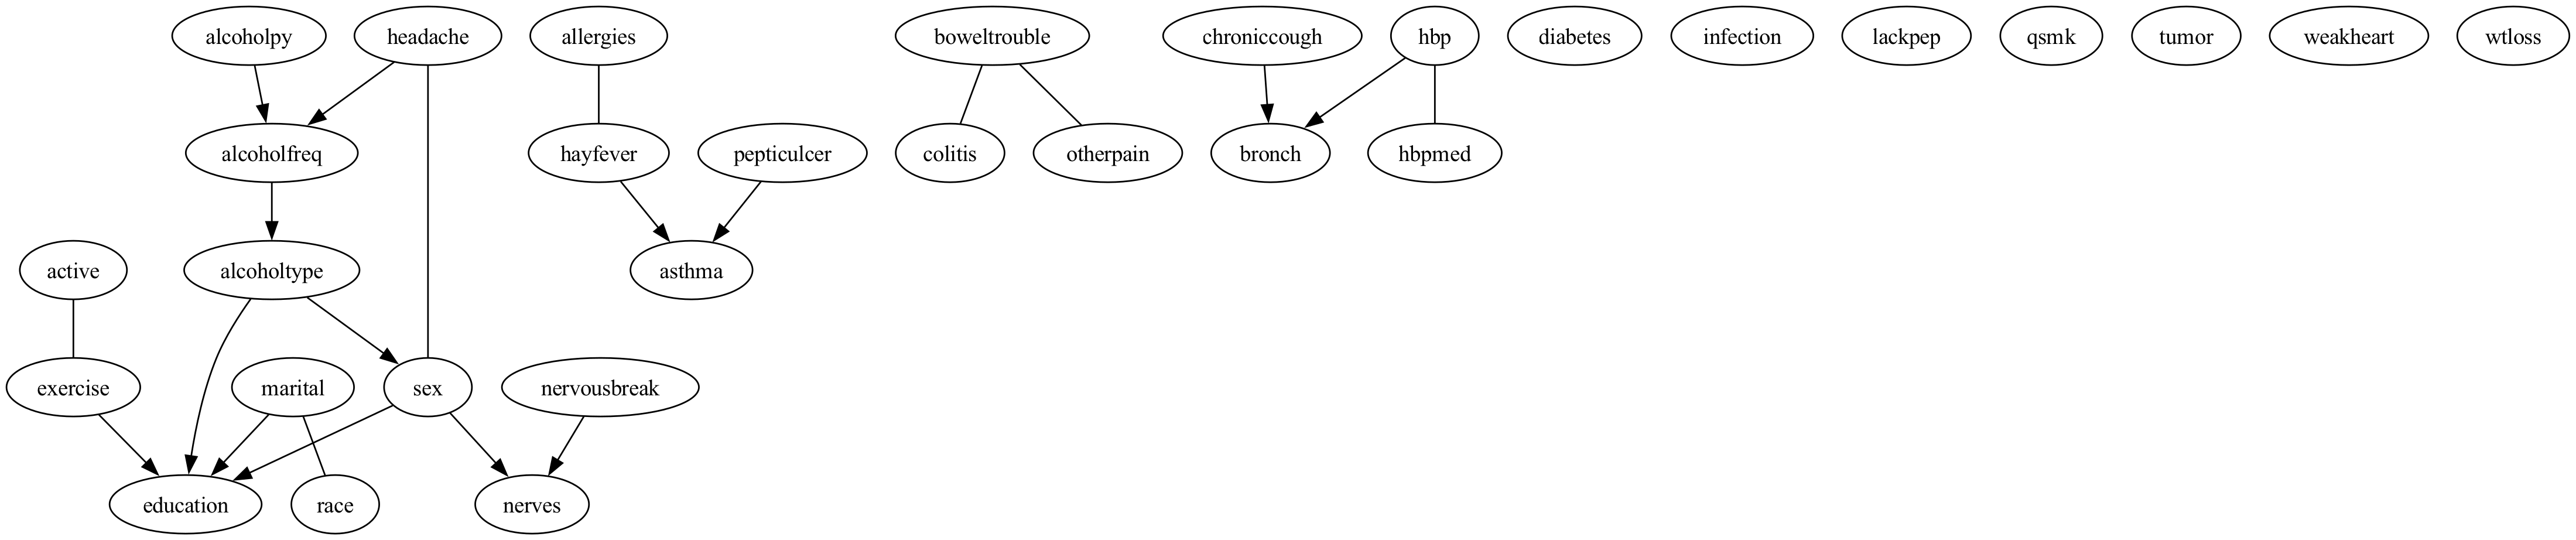


Chi-square alpha=0.05, edges involving qsmk:
  (qsmk is isolated)


In [31]:
chisq_vars = sorted(set(discrete_vars) | {'qsmk'})
chisq_data = df_clean[chisq_vars].values.astype(float)
chisq_labels = chisq_vars

cg_chi = pc(chisq_data, alpha=0.05, indep_test=chisq, stable=True,
            node_names=chisq_labels)

pdy_chi = GraphUtils.to_pydot(cg_chi.G, labels=chisq_labels)
pdy_chi.write_png("../outputs/figures/cpdag_chisq_05.png")
display(Image("../outputs/figures/cpdag_chisq_05.png"))

e_chi = extract_edges(cg_chi, chisq_labels, ['qsmk'])
print("\nChi-square alpha=0.05, edges involving qsmk:")
for e in e_chi:
    print(f"  {e}")
if not e_chi:
    print("  (qsmk is isolated)")

all_chi = extract_edges(cg_chi, chisq_labels)
pd.DataFrame({'method': 'Chi-square', 'alpha': 0.05, 'edge': all_chi if all_chi else ['(none)']}).to_csv(
    "../outputs/tables/edges_chisq.csv", index=False)

**Interpretation.** The discrete-variable graph is mainly a baseline diagnostic. It can reveal clusters among health and behavior variables, but it is not the main basis for orienting the treatment-outcome relation because `wt82_71` is continuous and therefore excluded from this run.

## 9. Tiered PC with KCI (mixed data, main result)

> KCI is the main discovery run because it can accommodate nonlinear and non-Gaussian relationships without the Gaussianity assumption used by Fisher-z. We use the same smaller variable set and the same temporal background knowledge as above. By default the code uses all available complete cases after harmonizing missingness; if runtime is too long on your machine, you can set `subsample_n` below to a smaller number.

Running tiered KCI-based PC on 761 observations and 14 variables...


  0%|          | 0/14 [00:00<?, ?it/s]

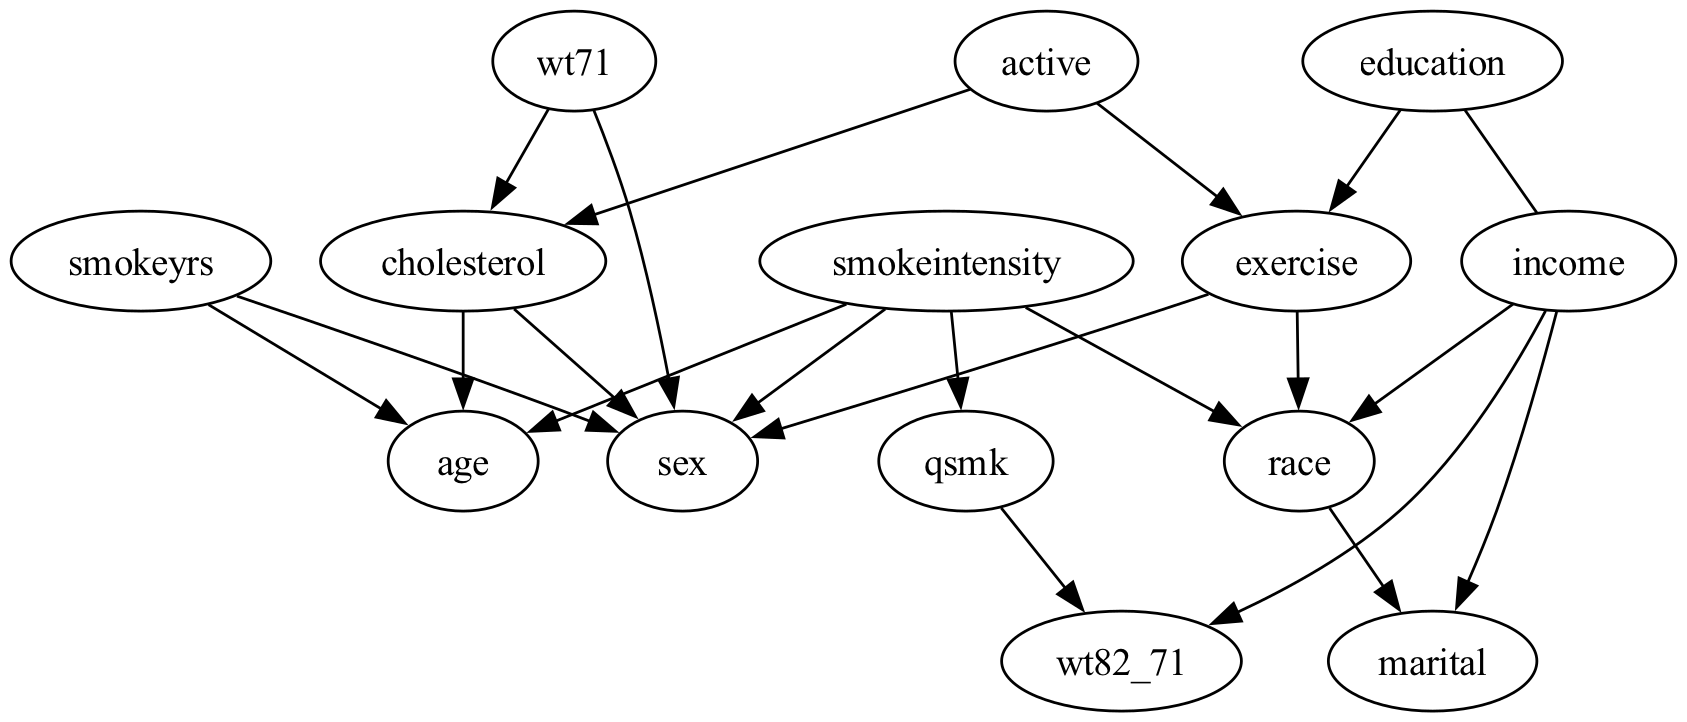


Tiered KCI alpha=0.05, edges involving qsmk or wt82_71:
  income -> wt82_71
  smokeintensity -> qsmk
  qsmk -> wt82_71


In [32]:
kci_vars = pc_vars_main.copy()
kci_labels = kci_vars

# By default use all available complete cases. If runtime is too long, set e.g. subsample_n = 800.
subsample_n = None
if subsample_n is not None and subsample_n < len(df_pc):
    df_kci = df_pc.sample(subsample_n, random_state=42)
else:
    df_kci = df_pc.copy()

kci_data = df_kci[kci_vars].values.astype(float)

print(f"Running tiered KCI-based PC on {len(df_kci)} observations and {len(kci_vars)} variables...")
cg_kci = pc(
    kci_data,
    alpha=0.05,
    indep_test=kci,
    stable=True,
    background_knowledge=bk_main,
    node_names=kci_labels,
    cache_path="../outputs/tables/kci_pc_cache.json"
)

pdy_kci = GraphUtils.to_pydot(cg_kci.G, labels=kci_labels)
pdy_kci.write_png("../outputs/figures/cpdag_kci_05_tiered.png")
display(Image("../outputs/figures/cpdag_kci_05_tiered.png"))

e_kci = extract_edges(cg_kci, kci_labels, ['qsmk', 'wt82_71'])
print("\nTiered KCI alpha=0.05, edges involving qsmk or wt82_71:")
for e in e_kci:
    print(f"  {e}")
if not e_kci:
    print("  (no edges involving qsmk or wt82_71 in this run)")

pd.DataFrame({'method': 'KCI_tiered', 'alpha': 0.05, 'edge': e_kci if e_kci else ['(none)']}).to_csv(
    "../outputs/tables/edges_kci_tiered.csv", index=False)

**Interpretation.** This is the main graph to inspect. Because the run uses harmonized missingness, a smaller pre-treatment set, and temporal background knowledge, it is much better aligned with the study design than an unconstrained PC run. In particular, any edge between `qsmk` and `wt82_71` can no longer be oriented in the implausible reverse direction.

The KCI graph should still be treated as exploratory rather than definitive. It suggests a dependence structure that is compatible with the data and the time ordering, but the final causal DAG for the report should also be checked against substantive knowledge from the smoking-cessation literature.

## 10. Summary Comparison

In [33]:
def get_neighbors(cg, labels, node):
    """Get neighbors of a node with edge type information."""
    if node not in labels:
        return 'N/A'
    g = cg.G.graph
    idx = labels.index(node)
    neighbors = []
    for j in range(len(labels)):
        if j == idx:
            continue
        if g[idx, j] != 0 or g[j, idx] != 0:
            if g[idx, j] == -1 and g[j, idx] == 1:
                neighbors.append(f"{node} -> {labels[j]}")
            elif g[idx, j] == 1 and g[j, idx] == -1:
                neighbors.append(f"{labels[j]} -> {node}")
            elif g[idx, j] == -1 and g[j, idx] == -1:
                neighbors.append(f"{node} -- {labels[j]}")
            else:
                neighbors.append(f"{node} ? {labels[j]}")
    return "; ".join(neighbors) if neighbors else "(isolated)"

summary_rows = []
for label, cg_obj, lbl_list, alpha_val in [
    ('Fisher-z', cg_fz05, fisherz_labels, 0.05),
    ('Fisher-z', cg_fz01, fisherz_labels, 0.01),
    ('Chi-square', cg_chi, chisq_labels, 0.05),
    ('KCI', cg_kci, kci_labels, 0.05),
]:
    summary_rows.append({
        'method': label, 'alpha': alpha_val,
        'qsmk_neighbors': get_neighbors(cg_obj, lbl_list, 'qsmk'),
        'wt82_71_neighbors': get_neighbors(cg_obj, lbl_list, 'wt82_71')
    })

summary_df = pd.DataFrame(summary_rows)
print(summary_df.to_string(index=False))
summary_df.to_csv("../outputs/tables/edge_comparison.csv", index=False)

    method  alpha                                                         qsmk_neighbors                                wt82_71_neighbors
  Fisher-z   0.05 age -> qsmk; smokeintensity -> qsmk; exercise -> qsmk; qsmk -> wt82_71 age -> wt82_71; wt71 -> wt82_71; qsmk -> wt82_71
  Fisher-z   0.01                                           age -> qsmk; qsmk -> wt82_71 age -> wt82_71; wt71 -> wt82_71; qsmk -> wt82_71
Chi-square   0.05                                                             (isolated)                                              N/A
       KCI   0.05                                smokeintensity -> qsmk; qsmk -> wt82_71               income -> wt82_71; qsmk -> wt82_71


**Interpretation.** The most useful comparison is between the temporally constrained Fisher-z screen and the temporally constrained KCI graph. If a treatment-outcome or confounder edge appears in both, it is less likely to be a pure artifact of the conditional-independence test. Differences across methods should be expected because Fisher-z is only approximate here, whereas KCI is more flexible but computationally heavier.

Most importantly, the background-knowledge restrictions encode the study chronology: baseline variables precede treatment, and treatment precedes later weight change. This prevents obviously implausible directions and makes the learned graph more suitable as an exploratory input for the final expert-informed DAG.

## 11. Conclusion

The main lesson from this notebook is that unconstrained PC can produce scientifically implausible directions when it is applied mechanically to mixed observational data. After harmonizing coded missingness, reducing the variable set to plausible pre-treatment covariates, and imposing temporal background knowledge, the learned graph becomes much more interpretable. The tiered KCI run is therefore the preferred exploratory result in this notebook, while the Fisher-z graph should be treated only as a fast approximation. For the final project, the learned structure should be used to inform — not replace — an expert-specified DAG grounded in the study design and the smoking-cessation literature.

## 12. References

1. Spirtes P, Glymour C. An algorithm for fast recovery of sparse causal graphs. *Social Science Computer Review* 9(1):62-72, 1991.
2. Spirtes P, Glymour C, Scheines R. *Causation, Prediction, and Search*. 2nd ed. MIT Press, 2000.
3. Colombo D, Maathuis MH. Order-independent constraint-based causal structure learning. *Journal of Machine Learning Research* 15:3921-3962, 2014.
4. Tu R, Zhang C, Ackermann P, Mohan K, Kjellstrom H, Zhang K. Causal discovery in the presence of missing data. *Proceedings of Machine Learning Research* 89:1762-1770, 2019.
5. Gain A, Shpitser I. Structure learning under missing data. *Proceedings of Machine Learning Research* 72:121-132, 2018.
6. Zhang K, Peters J, Janzing D, Scholkopf B. Kernel-based conditional independence test and application in causal discovery. *UAI*, 804-813, 2011.
7. Chickering DM. Optimal structure identification with greedy search. *Journal of Machine Learning Research* 3:507-554, 2002.
8. Shimizu S, Hoyer PO, Hyvarinen A, Kerminen A. A linear non-Gaussian acyclic model for causal discovery. *Journal of Machine Learning Research* 7:2003-2030, 2006.
9. Hernan MA, Robins JM. *Causal Inference: What If*. Chapman and Hall/CRC, 2020.
10. Glymour C, Zhang K, Spirtes P. Review of causal discovery methods based on graphical models. *Frontiers in Genetics* 10:524, 2019.
11. VanderWeele TJ, Ding P. Sensitivity analysis in observational research: introducing the E-value. *Annals of Internal Medicine* 167(4):268-274, 2017.
12. Zheng Y, Huang B, Chen W, Ramsey J, Gong M, Cai R, Shimizu S, Spirtes P, Zhang K. causal-learn: Causal discovery in Python. *Journal of Machine Learning Research* 25(60):1-8, 2024.
13. Strobl EV, Zhang K, Visweswaran S. Approximate kernel-based conditional independence tests for fast discovery of conditional independencies. *Journal of Causal Inference* 7(1), 2019.
14. Colombo D, Maathuis MH, Kalisch M, Richardson TS. Learning high-dimensional directed acyclic graphs with latent and selection variables. *Annals of Statistics* 40(1):294-321, 2012.